# Tema 4 — $k$-NN y árboles de decisión
**Aprendizaje Automático** · Máster · ESII–UCLM · Sesión del 26 de octubre de 2026

Seis ejercicios. Cada uno termina con una **celda de comprobación**: si pasa, vas bien.
No cambies los nombres de las variables que se piden, que son los que comprueban esas celdas.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, train_test_split, StratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score

rng = np.random.default_rng(2627)
n = 400
antiguedad = rng.uniform(0, 10, n)            # años como cliente: 0 a 10
ingresos   = rng.uniform(15000, 95000, n)     # euros al año: 15.000 a 95.000
y = (antiguedad + rng.normal(0, 1.2, n) > 5).astype(int)   # la clase depende SOLO de la antigüedad
X = np.c_[ingresos, antiguedad]
nombres = ["ingresos", "antiguedad"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
print(f"{len(X_tr)} ejemplos de entrenamiento, {len(X_te)} de test")
print("rangos -> ingresos: %.0f a %.0f   antiguedad: %.1f a %.1f"
      % (ingresos.min(), ingresos.max(), antiguedad.min(), antiguedad.max()))

280 ejemplos de entrenamiento, 120 de test
rangos -> ingresos: 15507 a 94906   antiguedad: 0.0 a 10.0


---
## Ejercicio 1 — El escalado no es opcional

Los dos atributos están en escalas muy distintas: los ingresos valen decenas de miles y la
antigüedad va de 0 a 10. Como $k$-NN **suma diferencias entre atributos**, los ingresos se van
a comer la distancia entera… y resulta que la clase depende solo de la antigüedad.

Calcula la exactitud media por validación cruzada de un $k$-NN con $k=5$ **sin escalar** y
**con `StandardScaler` dentro de un pipeline**.

> El escalador va *dentro* del pipeline, no antes: así se ajusta con el *train* de cada
> partición y no hay fuga de datos.

In [42]:
# acc_sin: k-NN con k=5 directamente sobre X_tr
# acc_con: k-NN con k=5 precedido de StandardScaler, dentro de un make_pipeline
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
exactitudes_sin = []
exactitudes_con = []
for i,j in kf.split(X_tr, y_tr):
    #SIN STANDARD SCALER
    modelo_sin = KNeighborsClassifier(n_neighbors=5)
    modelo_sin.fit(X_tr, y_tr)
    y_pred_sin = modelo_sin.predict(X_tr)
    exactitud_sin = accuracy_score(y_tr, y_pred_sin)
    exactitudes_sin.append(exactitud_sin)
    #CON STANDARD SCALER
    modelo_con = make_pipeline( StandardScaler(),KNeighborsClassifier(n_neighbors=5, weights="distance"))
    modelo_con.fit(X_tr, y_tr)
    y_pred_con = modelo_con.predict(X_tr)
    exactitud_con = accuracy_score(y_tr, y_pred_con)
    exactitudes_con.append(exactitud_con)
acc_sin = np.mean(exactitudes_sin)
acc_con = np.mean(exactitudes_con)
print(f"sin escalar: {acc_sin:.4f}    con escalado: {acc_con:.4f}    mejora: {acc_con-acc_sin:+.4f}")

sin escalar: 0.7179    con escalado: 1.0000    mejora: +0.2821


In [29]:
# comprobacion — no la modifiques
assert acc_con - acc_sin > 0.20, "el escalado debería mejorar muchísimo; revisa el pipeline"
print("OK 1 — el escalado sube la exactitud en mas de 20 puntos")

OK 1 — el escalado sube la exactitud en mas de 20 puntos


---
## Ejercicio 2 — Elegir $k$ por validación cruzada

$k$ es el mando que controla el compromiso sesgo–varianza, igual que $\lambda$ en el Tema 2.
Recórrelo y quédate con el mejor **mirando solo la validación cruzada, nunca el test**.

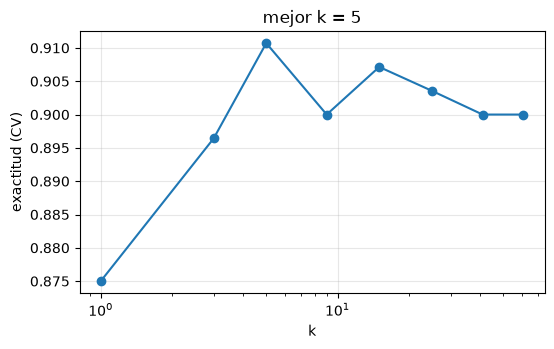

In [48]:
ks = [1, 3, 5, 9, 15, 25, 41, 61]
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = []
for i in ks:
    exactitudes = []
    for j, f in kf.split(X_tr, y_tr):
        modelo_con = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=i, weights="distance"))
        modelo_con.fit(X_tr[j], y_tr[j])
        y_pred_con = modelo_con.predict(X_tr[f])
        exactitud_con = accuracy_score(y_tr[f], y_pred_con)
        exactitudes.append(exactitud_con)
    scores.append(np.mean(exactitudes))
mejor_k = ks[np.argmax(scores)]
plt.figure(figsize=(6,3.4)); plt.plot(ks, scores, "o-")
plt.xscale("log"); plt.xlabel("k"); plt.ylabel("exactitud (CV)")
plt.title(f"mejor k = {mejor_k}"); plt.grid(alpha=.3); plt.show()

In [49]:
# comprobacion — no la modifiques
assert len(scores) == len(ks) and mejor_k in ks
assert scores[0] < max(scores), "con k=1 no deberia salir el mejor resultado"
print(f"OK 2 — mejor k = {mejor_k}; con k=1 la exactitud es {scores[0]:.4f}")

OK 2 — mejor k = 5; con k=1 la exactitud es 0.8750


---
## Ejercicio 3 — $k=1$ memoriza

Ajusta un $k$-NN con $k=1$ **sobre los datos escalados** y mide su exactitud en
entrenamiento y en test. El número de entrenamiento no es una sorpresa: es la definición
misma del método.

In [54]:
modelo_k1 = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=1, weights="distance"))
modelo_k1.fit(X_tr, y_tr)
y_pred_tr = modelo_k1.predict(X_tr)
y_pred_test = modelo_k1.predict(X_te)
acc_train = accuracy_score(y_tr, y_pred_tr)
acc_test = accuracy_score(y_te, y_pred_test)
print(f"k=1  ->  train {acc_train:.4f}   test {acc_test:.4f}")

k=1  ->  train 1.0000   test 0.8583


In [55]:
# comprobacion — no la modifiques
assert abs(acc_train - 1.0) < 1e-9, "con k=1 el error de entrenamiento tiene que ser exactamente 0"
assert acc_test < acc_train
print("OK 3 — train = 1.0000 y test por debajo: el modelo se memoriza a si mismo")

OK 3 — train = 1.0000 y test por debajo: el modelo se memoriza a si mismo


---
## Ejercicio 4 — Profundidad del árbol y sobreajuste

Los árboles no necesitan escalado: cada corte compara un atributo consigo mismo. Lo que sí
necesitan es que alguien les diga cuándo parar. Recorre `max_depth` y dibuja las dos curvas.

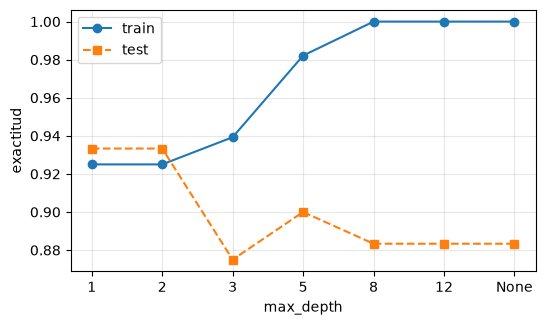

In [61]:
profundidades = [1, 2, 3, 5, 8, 12, None]
tr_acc, te_acc = [], []
for d in profundidades:

       # TU CÓDIGO AQUÍ: ajusta un DecisionTreeClassifier(max_depth=d, random_state=0)
          # y añade a tr_acc y te_acc sus exactitudes en train y en test
    modelo = DecisionTreeClassifier(max_depth=d, random_state=0)
    modelo.fit(X_tr, y_tr)
    y_pred_tr = modelo.predict(X_tr)
    y_pred_test = modelo.predict(X_te)
    tr_acc.append(accuracy_score(y_tr, y_pred_tr))
    te_acc.append(accuracy_score(y_te, y_pred_test))
etiq = [str(d) for d in profundidades]
plt.figure(figsize=(6,3.4))
plt.plot(etiq, tr_acc, "o-", label="train"); plt.plot(etiq, te_acc, "s--", label="test")
plt.xlabel("max_depth"); plt.ylabel("exactitud"); plt.legend(); plt.grid(alpha=.3); plt.show()

In [60]:
# comprobacion — no la modifiques
assert len(tr_acc) == len(profundidades)
assert all(tr_acc[i] <= tr_acc[i+1] + 1e-9 for i in range(len(tr_acc)-1)), \
       "la exactitud en train no puede bajar al profundizar"
assert abs(tr_acc[-1] - 1.0) < 1e-9, "el arbol sin podar deberia llegar a train = 1"
assert te_acc[-1] < max(te_acc), "el arbol sin podar deberia ser peor en test que alguno mas simple"
print(f"OK 4 — sin podar: train {tr_acc[-1]:.4f} / test {te_acc[-1]:.4f}; "
      f"el mejor test es {max(te_acc):.4f} con max_depth={etiq[int(np.argmax(te_acc))]}")

OK 4 — sin podar: train 1.0000 / test 0.8833; el mejor test es 0.9333 con max_depth=1


---
## Ejercicio 5 — La importancia por impureza se deja engañar

Añadimos una tercera columna, `identificador`, que es **una permutación aleatoria de 0 a 399**:
no tiene ninguna relación con la clase. Compara lo que dicen de ella `feature_importances_`
(impureza, calculada sobre el *train*) y `permutation_importance` (medida sobre datos no vistos).

Esto no estaba en los vídeos: está en las diapositivas 46 y 64 del tema.

In [67]:
identificador = rng.permutation(n).astype(float)
X2 = np.c_[X, identificador]; nombres2 = nombres + ["identificador"]
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y, test_size=0.3, random_state=0, stratify=y)

arbol2 = DecisionTreeClassifier(random_state=0)        # TU CÓDIGO AQUÍ: DecisionTreeClassifier(random_state=0) ajustado
arbol2.fit(X2_tr,y2_tr)
imp_impureza = arbol2.feature_importances_  # TU CÓDIGO AQUÍ
imp_perm = permutation_importance(arbol2, X2_te, y2_te, n_repeats=20, random_state=0).importances_mean      # TU CÓDIGO AQUÍ (permutation_importance sobre X2_te, n_repeats=20, random_state=0)

for nm, a, b in zip(nombres2, imp_impureza, imp_perm):
    print(f"{nm:15s} impureza = {a:.4f}     permutacion = {b:+.4f}")

ingresos        impureza = 0.0726     permutacion = -0.0133
antiguedad      impureza = 0.8747     permutacion = +0.3663
identificador   impureza = 0.0527     permutacion = -0.0246


In [68]:
# comprobacion — no la modifiques
i_id = nombres2.index("identificador")
assert imp_impureza[i_id] > 0.01, "el identificador deberia llevarse algo de importancia por impureza"
assert imp_perm[i_id] < 0.02, "por permutacion el identificador deberia quedarse en nada"
print(f"OK 5 — el identificador se lleva {imp_impureza[i_id]:.1%} de la importancia por impureza "
      f"y {imp_perm[i_id]:+.4f} por permutacion. La primera medida se deja enganar.")

OK 5 — el identificador se lleva 5.3% de la importancia por impureza y -0.0246 por permutacion. La primera medida se deja enganar.


---
## Para entregar

Esta libreta con **todos los TODO completos** y todas las celdas de comprobación en verde.
Plazo: **lunes 9 de noviembre a las 17:00** en el Campus Virtual, sección *Prácticas → Libretas*.